# Problem set 5: Printing and plotting

We use the CES consumer from the lectures to practise printing, files and plotting: a utility table, indifference curves, an income distribution and a budget set. The same CES function returns in Problem set 6. Below each task, a cell imports the answer (`A1.py`, `A2.py`, ...) and shows the target output.

**Learning goals**:

- Print results with f-strings: widths, decimals and thousands separators
- Build a text table with a nested loop and a function passed as an argument
- Write, append and read text files with `'w'`, `'a'` and `'r'`
- Plot lines, histograms and scatter plots with labels, legends, colors and line styles, and save them with `fig.savefig`
- Select data with Boolean masks and build a grid with `np.meshgrid`
- Optional: draw a 3D surface with `plot_surface`

**Table of contents**<a id='toc0_'></a>    
- 1. [CES utility](#toc1_)    
- 2. [A readable utility table](#toc2_)    
- 3. [Save, append and read back](#toc3_)    
- 4. [Indifference curves](#toc4_)    
- 5. [Income distribution](#toc5_)    
- 6. [The budget set](#toc6_)    
- 7. [Optional: utility in 3D](#toc7_)    

<!-- vscode-jupyter-toc-config
	numbering=true
	anchor=true
	flat=false
	minLevel=2
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

Imports you will need:

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# predefine options for all plots
plt.rcParams.update({'axes.grid':True,'grid.color':'black','grid.alpha':'0.25','grid.linestyle':'-'})
plt.rcParams.update({'font.size': 14})

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

## 1. <a id='toc1_'></a>[CES utility](#toc0_)

Implement the CES utility function as `u_func(x1,x2,alpha=0.5,beta=1.0)`:

$$
u(x_1,x_2) = (\alpha x_1^{-\beta} + (1-\alpha) x_2^{-\beta})^{-1/\beta}, \qquad \beta > 0
$$

`x1` and `x2` are positional arguments, `alpha` and `beta` are keyword arguments with the defaults shown. Both quantities must be strictly positive: with $\beta>0$, a zero quantity means a negative power of zero. Write the formula so that `x1` and `x2` can also be NumPy arrays, which you need from Task 4 on.

Then print one evaluation with an f-string and three decimals, in the form `u(2.0, 4.0) = 2.667`.

In [2]:
# these values are used
x1 = 2.0
x2 = 4.0

In [3]:
# write your code here

In [4]:
import A1
A1.report(x1, x2)

u(2.0, 4.0) = 2.667


## 2. <a id='toc2_'></a>[A readable utility table](#toc0_)

Write a function `gen_table(x1_vec,x2_vec,u_func)` that **returns** a text table of $u(x_1,x_2)$. The header row shows the $x_2$ values, and each row starts with its $x_1$ value. Use width 8 for every column, one decimal for $x_1$ and $x_2$, and three decimals for $u$.

Two things are new compared with the lecture:

1. a loop inside a loop: one row per $x_1$, and inside it one column per $x_2$;
2. the utility function arrives as an argument. A function is an object and can be passed to another function (see *A function is an object* in the functions notebook), so `gen_table` works with any utility function.

The header is given below. The call passes your `u_func` from Task 1. (`f'{"":8s}'` is an empty string padded to width 8.)

**Question:** In the row $x_1 = 0.5$ the values rise with $x_2$ but seem to stop below 1. Why, and which bound holds for a general $x_1$?

In [5]:
# these values are used
x1_vec = [0.5, 1, 2, 4]
x2_vec = [1, 2, 3, 4, 5]

In [6]:
# complete the function (the header is given)

def gen_table(x1_vec, x2_vec, u_func):

    # a. empty text
    text = ''

    # b. top header: empty corner, then the x2 values
    text += f'{"":8s}'
    for x2 in x2_vec:
        text += f'{x2:8.1f}'
    text += '\n' # line shift

    # c. body: one row per x1 value
    # write your code here

    return text

# table = gen_table(x1_vec, x2_vec, u_func)
# print(table)

In [7]:
import A1, A2
print(A2.gen_table(x1_vec, x2_vec, A1.u_func))

             1.0     2.0     3.0     4.0     5.0
     0.5   0.667   0.800   0.857   0.889   0.909
     1.0   1.000   1.333   1.500   1.600   1.667
     2.0   1.333   2.000   2.400   2.667   2.857
     4.0   1.600   2.667   3.429   4.000   4.444


<details>
<summary><strong>Answer</strong></summary>

For $\alpha=0.5$ and $\beta=1$ the formula is $u = 1/(0.5/x_1 + 0.5/x_2)$, the *harmonic mean* of $x_1$ and $x_2$. The term $0.5/x_2$ is positive, so the denominator is larger than $0.5/x_1$ and $u < 2x_1$. For $x_1 = 0.5$ the bound is 1.0: the row rises from 0.667 to 0.909 but never reaches it, and $u \to 2x_1$ only as $x_2 \to \infty$. In general $u < x_1/\alpha^{1/\beta}$.

</details>

## 3. <a id='toc3_'></a>[Save, append and read back](#toc0_)

Use the table from Task 2 and work with the file `utility_table.txt`:

- **(a)** Write the table to the file with `'w'`.
- **(b)** Append one line with the parameters, `alpha = 0.50, beta = 1.00`, using `'a'`.
- **(c)** Read the file back and print it.
- **(d)** Predict before you try: what does the file contain if the cell for (a) is run twice? And if the cell for (b) is run twice?

Note that `gen_table` returns text without a final line shift. Add `'\n'` when you write it, otherwise the appended line sticks to the last row.

In [8]:
# these values are used
x1_vec = [0.5, 1, 2, 4]
x2_vec = [1, 2, 3, 4, 5]
alpha = 0.5
beta = 1.0

# the table from Task 2 (taken from the answer files, so you can start here even without Task 2)
import A1, A2
table = A2.gen_table(x1_vec, x2_vec, A1.u_func)

In [9]:
# write your code here

**(e) Challenge:** Write the same numbers as rows of a LaTeX table to `utility_table.tex`, one row per $x_1$: 

```
0.5 & 0.667 & 0.800 & 0.857 & 0.889 & 0.909 \\
```

Build each row with a raw f-string, `fr'... \\'`, as in section 3.1 of the printing notebook. `' & '.join(list_of_strings)` glues a list of strings together with ` & ` between them. A starter:

In [10]:
# with open('utility_table.tex', 'w') as f:
#     for x1 in x1_vec:
#         cells = ' & '.join([f'{u_func(x1,x2):.3f}' for x2 in x2_vec]) # 'a & b & c'
#         # write one row with a raw f-string here

In [11]:
import A3
A3.write_table('utility_table.txt', table)             # (a)
A3.append_parameters('utility_table.txt', alpha, beta) # (b)
A3.read_and_print('utility_table.txt')                 # (c)

A3.write_latex('utility_table.tex', x1_vec, x2_vec, A1.u_func) # (e)
A3.read_and_print('utility_table.tex')

             1.0     2.0     3.0     4.0     5.0
     0.5   0.667   0.800   0.857   0.889   0.909
     1.0   1.000   1.333   1.500   1.600   1.667
     2.0   1.333   2.000   2.400   2.667   2.857
     4.0   1.600   2.667   3.429   4.000   4.444
alpha = 0.50, beta = 1.00
0.5 & 0.667 & 0.800 & 0.857 & 0.889 & 0.909 \\
1.0 & 1.000 & 1.333 & 1.500 & 1.600 & 1.667 \\
2.0 & 1.333 & 2.000 & 2.400 & 2.667 & 2.857 \\
4.0 & 1.600 & 2.667 & 3.429 & 4.000 & 4.444 \\


<details>
<summary><strong>Answer</strong></summary>

**(d)** Running (a) twice changes nothing: `'w'` replaces the file, so it holds the table once. Running (b) twice adds the parameter line twice, because `'a'` keeps the old content and writes after it. Running (a) again, and then (b), resets the file.

</details>

## 4. <a id='toc4_'></a>[Indifference curves](#toc0_)

An indifference curve contains all bundles with the same utility $u$. Solving $u(x_1,x_2)=u$ for $x_2$ gives

$$
x_2(x_1, u) = \left( \frac{u^{-\beta} - \alpha x_1^{-\beta}}{1-\alpha} \right)^{-1/\beta}
$$

which is only defined for $x_1 > u\,\alpha^{1/\beta}$ (otherwise the base is negative).

- **(a)** Implement `x2_func(x1,u,alpha=0.5,beta=1.0)` and check it with the cell below. Then plot the curves for $\beta=1$ and $u \in \{1.5, 2.0, 2.5\}$: one color per $u$, a label for each curve, a legend, and both axes from 0 to 4. Use a Boolean mask (Lecture 4) to keep only the $x_1$ values where the curve is defined.
- **(b)** Add the curves for $\beta=0.5$ (dashed, `'--'`) and $\beta=2.0$ (dotted, `':'`), and a 45-degree line. Save the figure as a PNG.

**Questions:** Why do all curves with the same $u$ cross the 45-degree line at the same point, whatever $\beta$ is? What does a larger $\beta$ do to the curvature?

In [12]:
# these values are used
alpha = 0.5
betas = [1.0, 0.5, 2.0]
uvals = [1.5, 2.0, 2.5]
x1_vec = np.linspace(0.1, 4.0, 1000)

In [13]:
def x2_func(x1, u, alpha=0.5, beta=1.0):
    pass

# write your code here

**Check:** if `x2_func` is right, it recovers $x_2$ from the utility of a bundle. Remove the `#` once `u_func` from Task 1 and `x2_func` exist:

In [14]:
# x1_ = 2.0
# x2_ = 1.5
# u_ = u_func(x1_, x2_, alpha=alpha, beta=1.0)
# print(np.isclose(x2_func(x1_, u_, alpha=alpha, beta=1.0), x2_)) # should print True

True


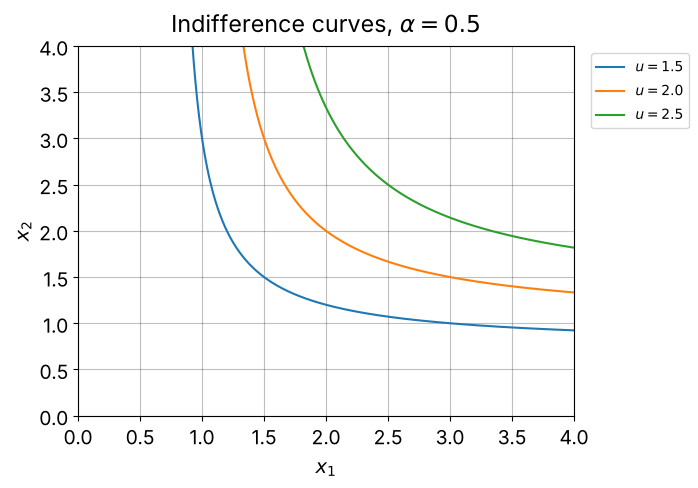

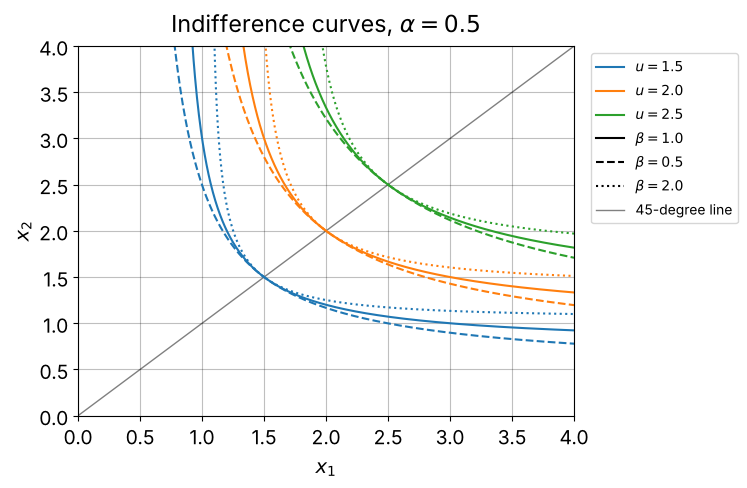

In [15]:
import A1, A4

x1_ = 2.0
x2_ = 1.5
u_ = A1.u_func(x1_, x2_, alpha=alpha, beta=1.0)
print(np.isclose(A4.x2_func(x1_, u_, alpha=alpha, beta=1.0), x2_))

A4.plot(alpha, [betas[0]], uvals, x1_vec)                                                  # (a)
A4.plot(alpha, betas, uvals, x1_vec, line45=True, filename='A4_indifference_curves.png')   # (b)

<details>
<summary><strong>Answer</strong></summary>

**45-degree line:** At $x_1=x_2=x$ the utility is $(\alpha x^{-\beta} + (1-\alpha) x^{-\beta})^{-1/\beta} = (x^{-\beta})^{-1/\beta} = x$. So the bundle $(u,u)$ has utility $u$ for every $\beta$, and every curve with that $u$ passes through it.

**Curvature:** A larger $\beta$ bends the curves more. At $\beta=2$ (dotted) the curves are close to a right angle around the 45-degree line: the goods are poor substitutes. At $\beta=0.5$ (dashed) the curves are flatter, so the goods substitute for each other more easily.

</details>

## 5. <a id='toc5_'></a>[Income distribution](#toc0_)

Incomes are right-skewed. The cell below simulates the annual incomes of 2000 households in DKK.

Plot a histogram of the incomes with 40 bins. Show income in thousand DKK (divide by 1000, so the axis stays readable) and label the axes. Add a vertical line at the mean and one at the median with `ax.axvline` (section 5.1 of the plotting notebook), use different colors or line styles, and add a legend. Save the figure.

Print the mean and the median with f-strings, for example `mean income: 334,669 DKK`. The format `:,.0f` writes a number with thousands separators and no decimals. Use `np.mean` and `np.median`.

**Question:** Why is the mean above the median?

In [16]:
# these values are used
rng = np.random.default_rng(2026)
N = 2000
income = 300_000*np.exp(rng.normal(0, 0.5, N)) # DKK per year

In [17]:
# write your code here

mean income:      334,669 DKK
median income:    295,372 DKK


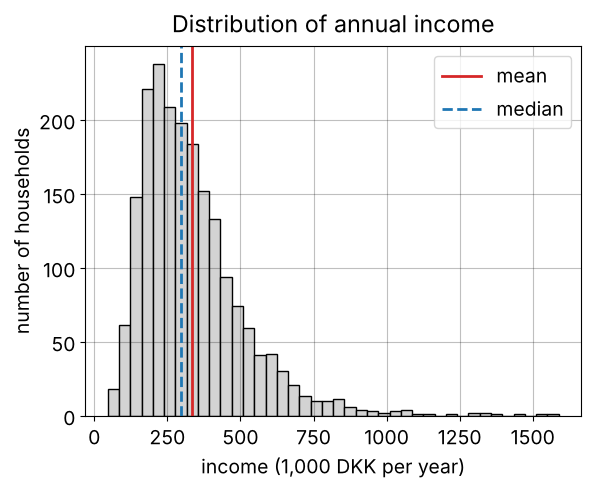

In [18]:
import A5
A5.summary(income)
A5.plot(income, filename='A5_income_histogram.png')

<details>
<summary><strong>Answer</strong></summary>

The distribution is skewed to the right: a few households with very high incomes form the long tail. They pull the mean up, while the median, the middle observation, hardly reacts to them. The mean is therefore above the median (here about 334,669 against 295,372 DKK). For a symmetric distribution the two would be close.

</details>

## 6. <a id='toc6_'></a>[The budget set](#toc0_)

A consumer has income $I$ and faces the prices $p_1$ and $p_2$. A bundle $(x_1,x_2)$ is **affordable** if

$$
p_1 x_1 + p_2 x_2 \leq I
$$

The starter cell sets up a grid of bundles. `np.meshgrid` returns two 2-D arrays, `x1_grid` and `x2_grid`, that together list every pair $(x_1,x_2)$ of the grid (see section 5.3 of the plotting notebook). Then:

- **(a)** Select the affordable bundles with a 2-D Boolean mask. *Hint:* indexing a 2-D array with a 2-D mask returns a 1-D array. How many of the 10,000 bundles are affordable?
- **(b)** Make a scatter plot of the affordable bundles, colored by their utility from Task 1, with a colorbar.
- **(c)** Add the budget line $p_1 x_1 + p_2 x_2 = I$.
- **(d)** Add the indifference curves for $u=3.0$ and $u=4.0$, using `x2_func` from Task 4 (or `from A4 import x2_func`) and only the $x_1$ where it is defined.

**Questions:** Which of the two utility levels can the consumer reach? Roughly where is the best affordable bundle?

In [19]:
# these values are used
p1 = 2.0
p2 = 1.0
income = 10.0
alpha = 0.5
beta = 1.0
uvals = [3.0, 4.0]

# grid of bundles (start slightly above 0, because u_func needs x > 0)
N = 100
x1_vec = np.linspace(0.05, income/p1, N)
x2_vec = np.linspace(0.05, income/p2, N)
x1_grid, x2_grid = np.meshgrid(x1_vec, x2_vec, indexing='ij') # first index belongs to x1

In [20]:
# write your code here

4950 of 10000 grid bundles are affordable


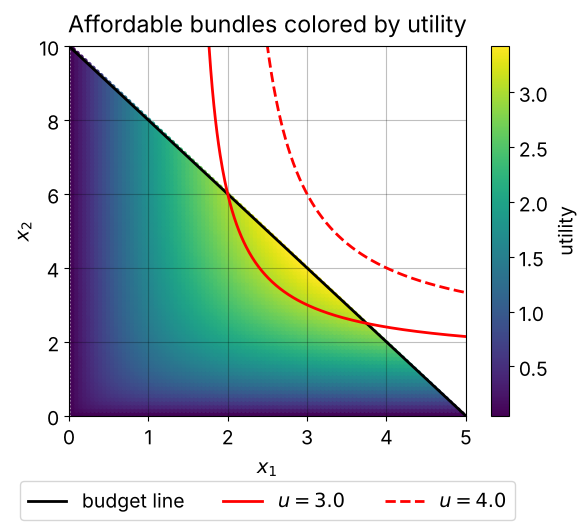

In [21]:
import A6
A6.plot(p1, p2, income, alpha, beta, uvals, N=N, filename='A6_budget_set.png')

<details>
<summary><strong>Answer</strong></summary>

The curve for $u=3$ cuts through the affordable set: it meets the budget line at $(2.0,\,6.0)$ and $(3.75,\,2.5)$, and the bundles on the budget line between these points give more than 3. The curve for $u=4$ lies entirely above the budget line, so 4 is out of reach. The best affordable bundle lies on the budget line, where an indifference curve just touches it: roughly $x_1 \approx 2.9$, $x_2 \approx 4.1$ with $u \approx 3.4$. The exact values are $x_1 = 2.929$, $x_2 = 4.142$ and $u = 3.431$. They come from the first-order condition worked out by hand; in Lecture 6 you find them numerically.

</details>

## 7. <a id='toc7_'></a>[Optional: utility in 3D](#toc0_)

**Optional, and beyond the core lecture.** This task uses the reference sections 5.2 (`zorder`) and 5.3 (3D plots) of the plotting notebook. Skip it if time is short.

Draw $u(x_1,x_2)$ as a surface and put indifference curves on it.

1. Compute $u$ on the grid from `np.meshgrid`.
2. Draw the surface with `ax.plot_surface` on a 3D axis and add a colorbar.
3. Draw black indifference curves for $u \in \{1,2,3\}$. A curve consists of the points $(x_1,\,x_2(x_1,u),\,u)$, so use the 3-D `ax.plot(x, y, z)` where `z` equals the constant $u$ at every point. Use `x2_func` from Task 4 (or `from A4 import x2_func`), keep only the $x_1$ where it is defined, and drop points with $x_2$ above the grid.

*Hints:* Without `zorder=99` in the line plot, the surface hides the curves. `ax.invert_xaxis()` brings the origin to the front and is optional.

In [22]:
# these values are used
from mpl_toolkits.mplot3d import Axes3D # for 3D plots
from matplotlib import cm # for colormaps

alpha = 0.5
beta = 1.0
x1_vec = np.linspace(0.1, 4.0, 1000)
x2_vec = np.linspace(0.1, 4.0, 1000)
uvals = [1.0, 2.0, 3.0]

In [23]:
# write your code here

# x1_grid, x2_grid = 
# u_grid = 

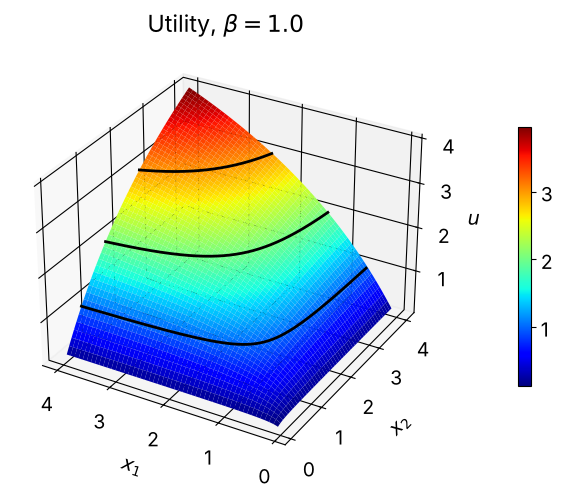

In [24]:
import A7
A7.plot(x1_vec, x2_vec, alpha, beta, uvals, filename='A7_utility_3d.png')

**Part B:** Repeat for $\beta = 2$ and compare the two figures.

In [25]:
# write your code here

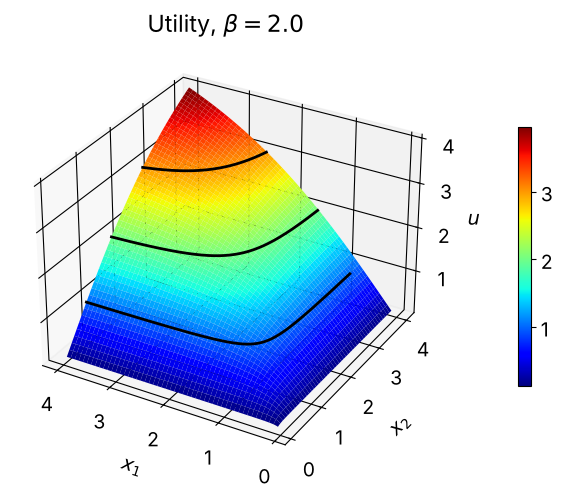

In [26]:
A7.plot(x1_vec, x2_vec, alpha, 2.0, uvals, filename='A7_utility_3d_beta2.png')

<details>
<summary><strong>Comment</strong></summary>

The two surfaces look alike. The difference is in the black curves: for $\beta=2$ they are closer to a right angle, as in Task 4. For example, the $u=3$ curve enters the grid (at $x_2=4$) at $x_1 \approx 2.50$ for $\beta=2$ against $x_1 \approx 2.40$ for $\beta=1$, closer to the corner at $(3,3)$.

</details>